# $Perceptron$ $Trick$

It tells us that misclassified points will pull the line to make the correct prediction.
i.e. moving the line in such a way that the positive lies in the positive direction and negative lies in the negative direction with respect to that line.

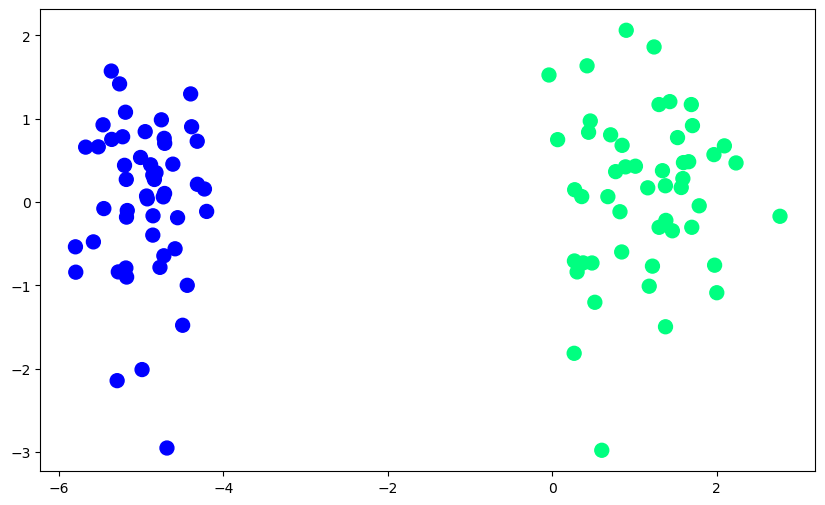

In [1]:
from sklearn.datasets import make_classification
import numpy as np


X, y = make_classification(n_samples=100, n_features=2,
                           n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1,
                           random_state=41,hypercube=False,class_sep=30)


import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [2]:
def perceptron(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
        
    return weights[0],weights[1:]
        

In [3]:
def step(z):
    return 1 if z>0 else 0


intercept_,coef_ = perceptron(X,y)
print(coef_)
print(intercept_)

[1.1204053  0.40381514]
1.2000000000000002


(-3.0, 2.0)

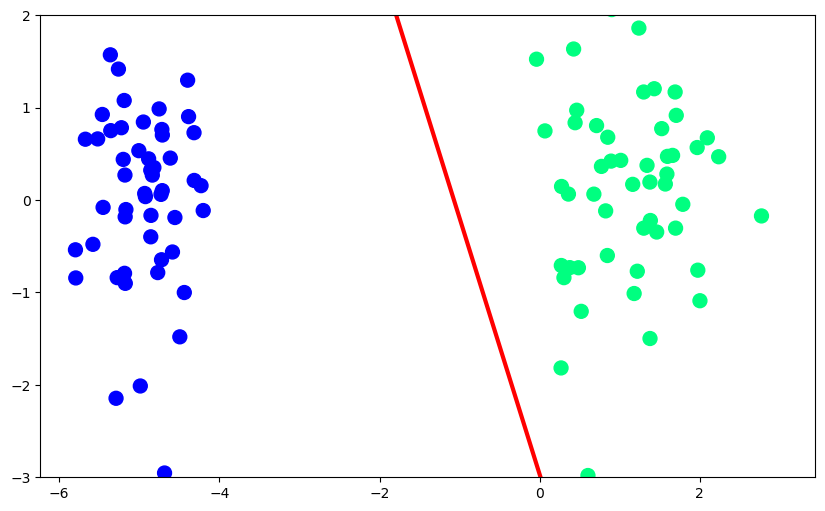

In [4]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

x_input = np.linspace(-3,3,100)
y_input = m*x_input + b


plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

(-3.0, 2.0)

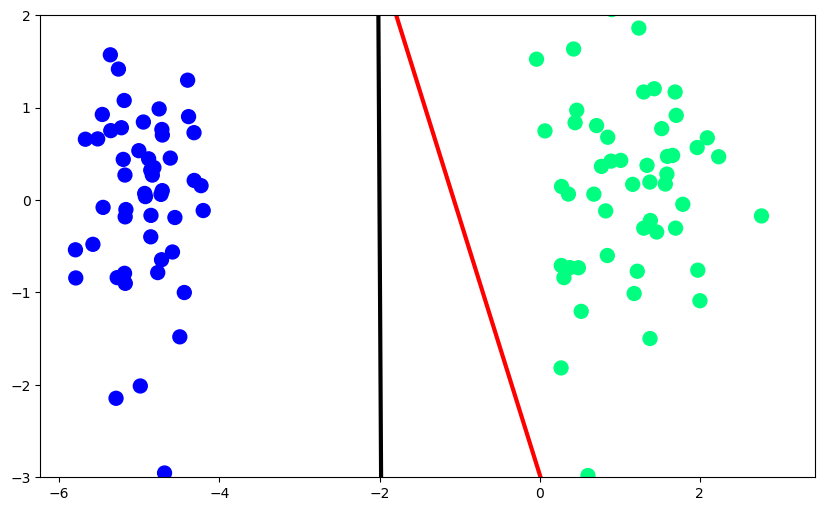

In [5]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression()
lor.fit(X,y)


m = -(lor.coef_[0][0]/lor.coef_[0][1])
b = -(lor.intercept_/lor.coef_[0][1])


x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input + b


plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

# $Sigmoid$ $Function$

The Betterment of Perceptron method. In this method we not only look toward the misclassified points but also toward the correctly classified points. In this method, what we do is:
1. The correctly classified points will try to push the line away from them
2. The wrongly classified points will try to pull the line toward themselves

in order to make all the hyperparameters right.
i.e., making the positive points on the positive side and making the negative points towards the negative side of the line.

This push and pull of the line not only depends on whether the points are classified correctly or not but in addition to this we also have the condition of the distance from the correctly classified or misclassified point. 

In case of misclassified points:
- The more the distance, the stronger the pull
- The shorter the distance, the weaker the pull


In case of correctly classified points it is just topsy-turvy of the previous statement. That is:
- Longer the distance, weaker the push
- Shorter the distance, stronger the push

In [6]:
def perceptron(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = sigmoid(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
        
    return weights[0],weights[1:]

(-3.0, 2.0)

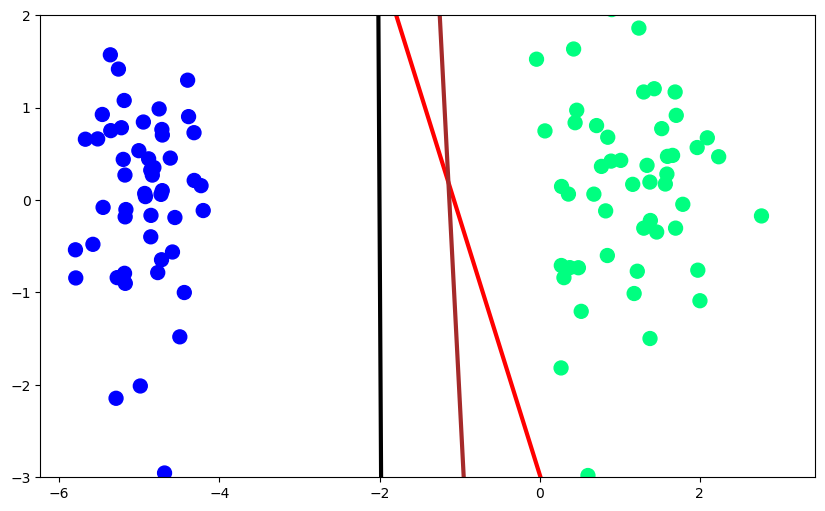

In [7]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))


intercept_,coef_ = perceptron(X,y)


m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])


x_input2 = np.linspace(-3,3,100)
y_input2 = m*x_input + b



plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.plot(x_input2,y_input2,color='brown',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [8]:
def perceptron(X,y):
    
    m = []
    b = []
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(200):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
        
        m.append(-(weights[1]/weights[2]))
        b.append(-(weights[0]/weights[2]))
        
    return m,b

In [12]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9,5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)
line, = ax.plot(x_i, x_i*m[0] + b[0], 'r-', linewidth=2)
plt.ylim(-3,3)

def update(i):
    label = f'epoch {i+1}'
    line.set_ydata(x_i*m[i] + b[i])
    ax.set_xlabel(label)
    return line,

anim = FuncAnimation(fig, update, frames=len(m), interval=100)

HTML(anim.to_jshtml())


<IPython.core.display.Javascript object>